In [8]:
# 1. Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


# 2. Create a sample dataset

data = {
    'Player': ['P1', 'P2', 'P3', 'P4', 'P5',
               'P6', 'P7', 'P8', 'P9', 'P10',
               'P11', 'P12', 'P13', 'P14', 'P15',
               'P16', 'P17', 'P18', 'P19', 'P20'],

    'Runs': [12, 25, 35, 42, 18,
             55, 60, 28, 45, 38,
             50, 65, 32, 48, 40,
             72, 58, 250, 280, 5]
}

df = pd.DataFrame(data)

# Display the dataset
print(df)

   Player  Runs
0      P1    12
1      P2    25
2      P3    35
3      P4    42
4      P5    18
5      P6    55
6      P7    60
7      P8    28
8      P9    45
9     P10    38
10    P11    50
11    P12    65
12    P13    32
13    P14    48
14    P15    40
15    P16    72
16    P17    58
17    P18   250
18    P19   280
19    P20     5


In [7]:
%pip install seaborn

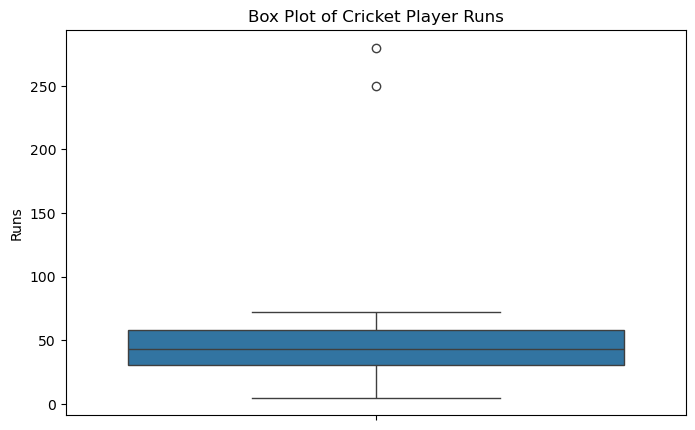

In [9]:
# 3. Visualize the data using a box plot

plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Runs'])

plt.title("Box Plot of Cricket Player Runs")
plt.ylabel("Runs")

plt.show()

In [10]:
# 4. Detect outliers using IQR

# Calculate Q1 and Q3
Q1 = df['Runs'].quantile(0.25)
Q3 = df['Runs'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

# Calculate IQR
IQR = Q3 - Q1

print("IQR =", IQR)

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# Identify outliers
outliers_iqr = df[
    (df['Runs'] < lower_limit) |
    (df['Runs'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr)

Q1 = 31.0
Q3 = 58.5
IQR = 27.5
Lower Limit = -10.25
Upper Limit = 99.75
Outliers detected using IQR:
   Player  Runs
17    P18   250
18    P19   280


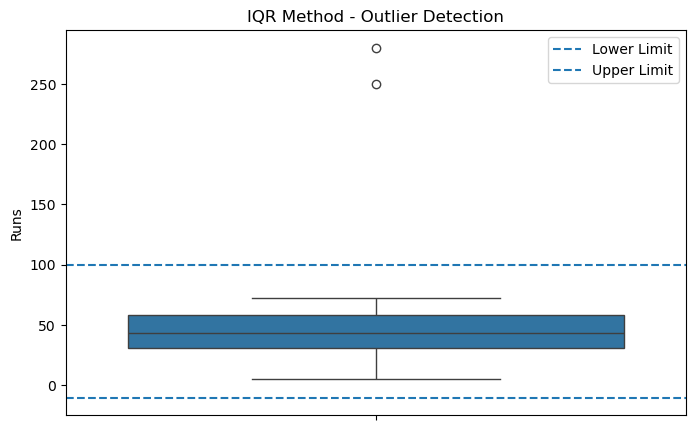

In [11]:
#Visualize the Outliers
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Runs'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()

In [14]:
#IQR Outlier Treatment – Capping

df['Runs_IQR_Capped'] = df['Runs'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['Runs', 'Runs_IQR_Capped']])

    Runs  Runs_IQR_Capped
0     12            12.00
1     25            25.00
2     35            35.00
3     42            42.00
4     18            18.00
5     55            55.00
6     60            60.00
7     28            28.00
8     45            45.00
9     38            38.00
10    50            50.00
11    65            65.00
12    32            32.00
13    48            48.00
14    40            40.00
15    72            72.00
16    58            58.00
17   250            99.75
18   280            99.75
19     5             5.00


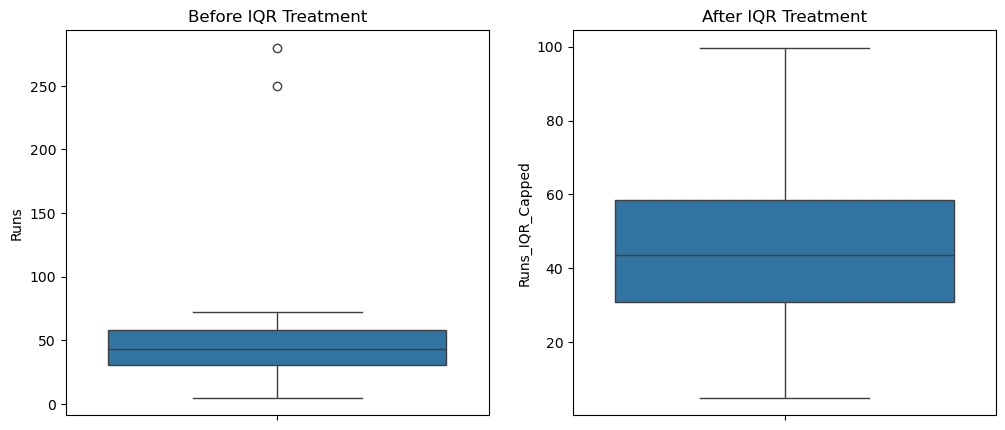

In [16]:
#visualize before and after treatment
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Runs'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Runs_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()

In [17]:
# 6. Calculate Z-scores

df['Z_score'] = stats.zscore(df['Runs'])

print(df[['Runs', 'Z_score']])


    Runs   Z_score
0     12 -0.731040
1     25 -0.544331
2     35 -0.400708
3     42 -0.300172
4     18 -0.644867
5     55 -0.113462
6     60 -0.041651
7     28 -0.501244
8     45 -0.257085
9     38 -0.357621
10    50 -0.185274
11    65  0.030161
12    32 -0.443795
13    48 -0.213998
14    40 -0.328896
15    72  0.130697
16    58 -0.070375
17   250  2.687184
18   280  3.118053
19     5 -0.831576


In [22]:
#identify the z-score outliers
Z_Outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(Z_Outliers)
df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['Runs', 'Z_score', 'Z_Outlier']])

Outliers detected using Z-score:
   Player  Runs  Runs_IQR_Capped   Z_score  Z_Outlier  Runs_Z_Capped
18    P19   280            99.75  3.118053       True      277.20674
    Runs   Z_score  Z_Outlier
0     12 -0.731040      False
1     25 -0.544331      False
2     35 -0.400708      False
3     42 -0.300172      False
4     18 -0.644867      False
5     55 -0.113462      False
6     60 -0.041651      False
7     28 -0.501244      False
8     45 -0.257085      False
9     38 -0.357621      False
10    50 -0.185274      False
11    65  0.030161      False
12    32 -0.443795      False
13    48 -0.213998      False
14    40 -0.328896      False
15    72  0.130697      False
16    58 -0.070375      False
17   250  2.687184      False
18   280  3.118053       True
19     5 -0.831576      False


In [19]:
#z-score outlier treatment-capping
mean = df['Runs'].mean()
std = df['Runs'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)


df['Runs_Z_Capped'] = df['Runs'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['Runs', 'Runs_Z_Capped']])

Lower Z-score limit = -151.4067403218303
Upper Z-score limit = 277.2067403218303
    Runs  Runs_Z_Capped
0     12       12.00000
1     25       25.00000
2     35       35.00000
3     42       42.00000
4     18       18.00000
5     55       55.00000
6     60       60.00000
7     28       28.00000
8     45       45.00000
9     38       38.00000
10    50       50.00000
11    65       65.00000
12    32       32.00000
13    48       48.00000
14    40       40.00000
15    72       72.00000
16    58       58.00000
17   250      250.00000
18   280      277.20674
19     5        5.00000


    Runs  Runs_IQR_Capped  Runs_Z_Capped
0     12            12.00       12.00000
1     25            25.00       25.00000
2     35            35.00       35.00000
3     42            42.00       42.00000
4     18            18.00       18.00000
5     55            55.00       55.00000
6     60            60.00       60.00000
7     28            28.00       28.00000
8     45            45.00       45.00000
9     38            38.00       38.00000
10    50            50.00       50.00000
11    65            65.00       65.00000
12    32            32.00       32.00000
13    48            48.00       48.00000
14    40            40.00       40.00000
15    72            72.00       72.00000
16    58            58.00       58.00000
17   250            99.75      250.00000
18   280            99.75      277.20674
19     5             5.00        5.00000


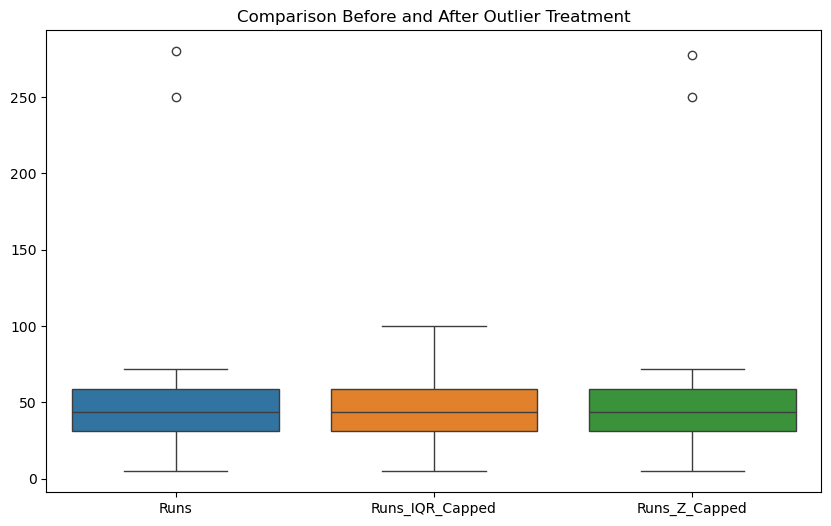

In [21]:
#compare the three version
print(df[['Runs', 
          'Runs_IQR_Capped', 
          'Runs_Z_Capped']])

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    ['Runs', 'Runs_IQR_Capped', 'Runs_Z_Capped']
])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()